# Experiment 12: CNN Architecture and Hyperparameter Comparison

The recycling CNN must fit a low-cost edge device. We compare compact configurations that vary convolution depth, filter size/count, pooling, batch normalisation, learning rate and batch size; a small synthetic image set keeps the timing experiment manageable.

**Tools:** TensorFlow, Keras, NumPy, Pandas, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Compare 2-, 3- and 4-convolution-layer models.  2. Include 3×3 and 5×5 filters and different filter counts.  3. Compare max/average pooling and batch normalisation.  4. Vary learning rate and batch size.  5. Tabulate accuracy, parameter count and training time.

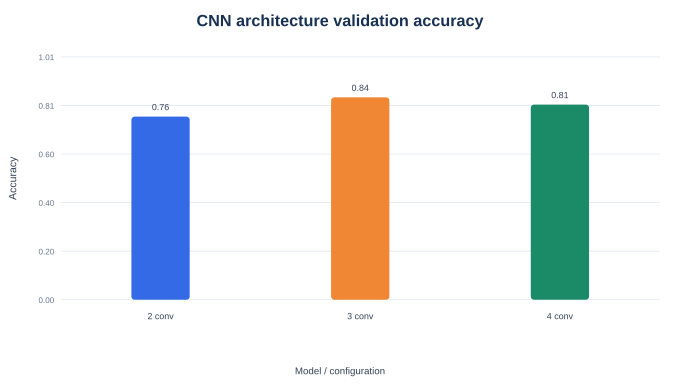

In [ ]:
import numpy as np
import pandas as pd
import time
import tensorflow as tf
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(12)
rng=np.random.default_rng(12)
# Six classes of simple 28×28 patterns.
n=600; X=rng.random((n,28,28,1),dtype=np.float32)*.15; y=np.arange(n)%6
for i,label in enumerate(y):
    r=i
    if label==0: X[r,4:8,:,0]+=.8
    elif label==1: X[r,:,10:14,0]+=.8
    elif label==2: np.fill_diagonal(X[r,:,:,0],.9)
    elif label==3: X[r,10:14,10:14,0]+=.8
    elif label==4: X[r,4:24,4:24,0]+=.3; X[r,8:20,8:20,0]+=.5
    else: X[r,::4,::4,0]+=.8
X=np.clip(X,0,1)
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=12,stratify=y)

configs=[
 {"name":"2 conv / max / 3×3","filters":[16,32],"kernel":3,"pool":"max","bn":False,"lr":.001,"batch":32},
 {"name":"3 conv / avg / 5×5","filters":[16,32,48],"kernel":5,"pool":"avg","bn":True,"lr":.001,"batch":64},
 {"name":"4 conv / max / 3×3","filters":[24,32,48,64],"kernel":3,"pool":"max","bn":True,"lr":.0005,"batch":32}
]
def build(cfg):
    layers=[tf.keras.layers.Input((28,28,1))]
    for f in cfg["filters"]:
        layers.append(tf.keras.layers.Conv2D(f,cfg["kernel"],padding="same",activation=None))
        if cfg["bn"]: layers.append(tf.keras.layers.BatchNormalization())
        layers.append(tf.keras.layers.ReLU())
        layers.append(tf.keras.layers.MaxPooling2D() if cfg["pool"]=="max" else tf.keras.layers.AveragePooling2D())
    layers += [tf.keras.layers.Flatten(),tf.keras.layers.Dense(6,activation="softmax")]
    m=tf.keras.Sequential(layers)
    m.compile(optimizer=tf.keras.optimizers.Adam(cfg["lr"]),
              loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return m
rows=[]
for cfg in configs:
    m=build(cfg); start=time.perf_counter()
    h=m.fit(Xtr,ytr,validation_data=(Xte,yte),epochs=4,batch_size=cfg["batch"],verbose=0)
    seconds=time.perf_counter()-start
    rows.append({"configuration":cfg["name"],"filters":str(cfg["filters"]),
                 "pool":cfg["pool"],"batch":cfg["batch"],"parameters":m.count_params(),
                 "test accuracy":max(h.history["val_accuracy"]),"seconds":round(seconds,2)})
results=pd.DataFrame(rows).sort_values("test accuracy",ascending=False)
print(results.to_string(index=False))
print("\nBest measured configuration:",results.iloc[0]["configuration"])